In [53]:
import pandas as pd

df_base_varejo = pd.read_csv("Base Varejo.csv", sep=";", encoding="latin1")

print(df_base_varejo.head())

         DATA  CO_ID  CL_ID CL_GENERO  CL_EC  CL_FHL CL_SEG  PR_ID     PR_CAT  \
0  01/02/2019   1000    534         M      4       1      C     67    BEBIDAS   
1  01/02/2019   1000    534         M      4       1      C     70    BEBIDAS   
2  01/02/2019   1000    534         M      4       1      C    178    HIGIENE   
3  01/02/2019   1000    534         M      4       1      C      4  ALIMENTOS   
4  01/02/2019   1000    534         M      4       1      C    175    LIMPEZA   

                PR_NOME  Unnamed: 10  Unnamed: 11  Unnamed: 12  Unnamed: 13  
0  REFRIGERANTE GUARANA          NaN          NaN          NaN          NaN  
1   REFRIGERANTE OUTROS          NaN          NaN          NaN          NaN  
2       LENCO UMEDECIDO          NaN          NaN          NaN          NaN  
3               ABACAXI          NaN          NaN          NaN          NaN  
4     LIMPADOR MULTIUSO          NaN          NaN          NaN          NaN  


In [54]:
df_base_varejo["DATA"] = pd.to_datetime(
    df_base_varejo["DATA"],
    format="%d/%m/%Y"
)

print(df_base_varejo["DATA"].dtype)

datetime64[us]


In [55]:
print("Data inicial:", df_base_varejo["DATA"].min())
print("Data final:", df_base_varejo["DATA"].max())

Data inicial: 2019-01-04 00:00:00
Data final: 2022-12-08 00:00:00


In [ ]:
#verificar registros de compras por ano

print(df_base_varejo["DATA"].dt.year.value_counts().sort_index())

DATA
2019    199036
2020    218367
2021    245259
2022    167338
Name: count, dtype: int64


In [57]:
#quantas colunas e linhas existem

print("Número de registros:", df_base_varejo.shape[0]) #linhas
print("Número de colunas:", df_base_varejo.shape[1]) #colunas

Número de registros: 830000
Número de colunas: 14


In [58]:
#tipos de dados

print(df_base_varejo.dtypes)

DATA           datetime64[us]
CO_ID                   int64
CL_ID                   int64
CL_GENERO                 str
CL_EC                   int64
CL_FHL                  int64
CL_SEG                    str
PR_ID                   int64
PR_CAT                    str
PR_NOME                   str
Unnamed: 10           float64
Unnamed: 11           float64
Unnamed: 12           float64
Unnamed: 13           float64
dtype: object


In [59]:
df_base_varejo.isna().sum() #valores ausentes em cada coluna

DATA                0
CO_ID               0
CL_ID               0
CL_GENERO           0
CL_EC               0
CL_FHL              0
CL_SEG              0
PR_ID               0
PR_CAT              0
PR_NOME             0
Unnamed: 10    830000
Unnamed: 11    830000
Unnamed: 12    830000
Unnamed: 13    830000
dtype: int64

In [60]:
df_base_varejo.duplicated().sum()

np.int64(96553)

In [61]:

print("Dimensões da base:", df_base_varejo.shape)

print("\nQuantidade de valores diferentes por coluna:")
print(df_base_varejo.nunique(dropna=False)) #conta os valores distintos nas colunas (ausentes tbm)

print("\nExemplos de colunas sem nome:")
print(df_base_varejo[
    ["Unnamed: 10", "Unnamed: 11", "Unnamed: 12", "Unnamed: 13"]
].head())


Dimensões da base: (830000, 14)

Quantidade de valores diferentes por coluna:
DATA             333
CO_ID          18471
CL_ID           1000
CL_GENERO          2
CL_EC              5
CL_FHL             5
CL_SEG             3
PR_ID            229
PR_CAT             7
PR_NOME          118
Unnamed: 10        1
Unnamed: 11        1
Unnamed: 12        1
Unnamed: 13        1
dtype: int64

Exemplos de colunas sem nome:
   Unnamed: 10  Unnamed: 11  Unnamed: 12  Unnamed: 13
0          NaN          NaN          NaN          NaN
1          NaN          NaN          NaN          NaN
2          NaN          NaN          NaN          NaN
3          NaN          NaN          NaN          NaN
4          NaN          NaN          NaN          NaN


In [62]:

df_base_varejo = df_base_varejo.dropna(axis=1, how="all") #remover só os dados da coluna


In [63]:

print("Dimensões após ter feito a limpeza:", df_base_varejo.shape)
print(df_base_varejo.columns)


Dimensões após ter feito a limpeza: (830000, 10)
Index(['DATA', 'CO_ID', 'CL_ID', 'CL_GENERO', 'CL_EC', 'CL_FHL', 'CL_SEG',
       'PR_ID', 'PR_CAT', 'PR_NOME'],
      dtype='str')


In [64]:
df_base_varejo.columns = df_base_varejo.columns.str.lower() #tudo minúsculo

print(df_base_varejo.columns)

Index(['data', 'co_id', 'cl_id', 'cl_genero', 'cl_ec', 'cl_fhl', 'cl_seg',
       'pr_id', 'pr_cat', 'pr_nome'],
      dtype='str')


In [65]:
#trocar a abreviação para nome da coluna pra entender melhor o que cada uma é
df_base_varejo = df_base_varejo.rename(columns={
    "data": "data_compra",
    "co_id": "numero_compra",
    "cl_id": "id_cliente",
    "cl_genero": "genero_cliente",
    "cl_ec": "estado_civil",
    "cl_fhl": "numero_filhos",
    "cl_seg": "segmento_economico",
    "pr_id": "sku_produto",
    "pr_cat": "categoria_produto",
    "pr_nome": "nome_produto"
})

print(df_base_varejo.columns)

Index(['data_compra', 'numero_compra', 'id_cliente', 'genero_cliente',
       'estado_civil', 'numero_filhos', 'segmento_economico', 'sku_produto',
       'categoria_produto', 'nome_produto'],
      dtype='str')


In [66]:

print(df_base_varejo["genero_cliente"].value_counts())


print(df_base_varejo["estado_civil"].value_counts().sort_index())


print(df_base_varejo["segmento_economico"].value_counts())


print(df_base_varejo["categoria_produto"].value_counts())

genero_cliente
F    432576
M    397424
Name: count, dtype: int64
estado_civil
1    194873
2    194990
3    213742
4    202618
5     23777
Name: count, dtype: int64
segmento_economico
B    530163
C    232101
A     67736
Name: count, dtype: int64
categoria_produto
ALIMENTOS     434767
HIGIENE       155574
LIMPEZA       145754
BEBIDAS        43299
PET            32399
ACESSORIOS     14557
#N/D            3650
Name: count, dtype: int64


In [67]:
registros_nd = df_base_varejo[
    df_base_varejo["categoria_produto"] == "#N/D"
]

print("Quantidade de registros:", len(registros_nd))
print(registros_nd.head(10))

Quantidade de registros: 3650
     data_compra  numero_compra  id_cliente genero_cliente  estado_civil  \
82    2019-02-01           1078         290              F             1   
223   2019-02-01           1103         957              M             2   
640   2019-02-01           1482         453              F             1   
857   2019-02-01           1683         438              F             1   
917   2019-02-01           1793         608              F             3   
1185  2019-02-01           2151         493              M             2   
1273  2019-02-01           2224         497              M             3   
1303  2019-02-01           2311         164              M             2   
1325  2019-02-01           2311         164              M             2   
1385  2019-02-01           2327         689              M             2   

      numero_filhos segmento_economico  sku_produto categoria_produto  \
82                0                  B          107         

In [ ]:
df_base_varejo.duplicated(keep=False).sum()

np.int64(184330)

In [69]:
df_base_varejo[df_base_varejo.duplicated(keep=False)].head(20)

,data_compra,numero_compra,id_cliente,genero_cliente,estado_civil,numero_filhos,segmento_economico,sku_produto,categoria_produto,nome_produto
3,2019-02-01,1000,534,M,4,1,C,4,ALIMENTOS,ABACAXI
7,2019-02-01,1000,534,M,4,1,C,11,ALIMENTOS,AZEITE
14,2019-02-01,1000,534,M,4,1,C,13,ALIMENTOS,BANANA
15,2019-02-01,1000,534,M,4,1,C,218,ALIMENTOS,BIFE DE COXAO MOLE
19,2019-02-01,1000,534,M,4,1,C,13,ALIMENTOS,BANANA
22,2019-02-01,1000,534,M,4,1,C,69,BEBIDAS,REFRIGERANTE LIMaO
34,2019-02-01,1000,534,M,4,1,C,225,ALIMENTOS,ATUM
40,2019-02-01,1000,534,M,4,1,C,4,ALIMENTOS,ABACAXI
46,2019-02-01,1000,534,M,4,1,C,11,ALIMENTOS,AZEITE
49,2019-02-01,1000,534,M,4,1,C,69,BEBIDAS,REFRIGERANTE LIMaO


In [ ]:
#repetidos do cliente 534 abacaxi, bebida de limao, azeite, bife de coxão mole, azeite, banana
#repetidos do cliente 290 chupeta e desinfetante

In [74]:
df_base_varejo = df_base_varejo.drop_duplicates()

In [75]:
df_base_varejo.drop_duplicates().shape

(733447, 10)

In [80]:
df_base_varejo.duplicated().sum()

np.int64(0)

In [81]:
df_base_varejo.isna().sum()

data_compra           0
numero_compra         0
id_cliente            0
genero_cliente        0
estado_civil          0
numero_filhos         0
segmento_economico    0
sku_produto           0
categoria_produto     0
nome_produto          0
dtype: int64

In [82]:
df_base_varejo.dtypes

data_compra           datetime64[us]
numero_compra                  int64
id_cliente                     int64
genero_cliente                   str
estado_civil                   int64
numero_filhos                  int64
segmento_economico               str
sku_produto                    int64
categoria_produto                str
nome_produto                     str
dtype: object

In [84]:
#contar quantos valores existem nas 3 colunas

print("Clientes:", df_base_varejo["id_cliente"].nunique())
print("Compras:", df_base_varejo["numero_compra"].nunique())
print("Produtos:", df_base_varejo["sku_produto"].nunique())

Clientes: 1000
Compras: 18471
Produtos: 229


In [ ]:
#verificar a data + antiga e a + recente de compra

print("Data inicial:", df_base_varejo["data_compra"].min())
print("Data final:", df_base_varejo["data_compra"].max())

Data inicial: 2019-01-04 00:00:00
Data final: 2022-12-08 00:00:00


In [ ]:
#verificar número de compras por ano

df_base_varejo["data_compra"].dt.year.value_counts().sort_index()

data_compra
2019    176103
2020    192804
2021    216813
2022    147727
Name: count, dtype: int64

In [89]:
df_base_varejo.describe()

,data_compra,numero_compra,id_cliente,estado_civil,numero_filhos,sku_produto
count,733447,733447.000000,733447.000000,733447.000000,733447.000000,733447.000000
mean,2020-12-06 11:20:27.215055,459941.034680,499.643996,2.597385,1.146049,115.037337
min,2019-01-04 00:00:00,1000.000000,1.000000,1.000000,0.000000,1.000000
25%,2020-01-09 00:00:00,232895.000000,254.000000,2.000000,0.000000,58.000000
50%,2020-12-27 00:00:00,456422.000000,498.000000,3.000000,0.000000,115.000000
75%,2021-10-20 00:00:00,690100.000000,746.000000,4.000000,2.000000,172.000000
max,2022-12-08 00:00:00,919822.000000,1000.000000,5.000000,4.000000,229.000000
std,NaN,265431.394822,287.561653,1.170130,1.416917,66.124263


In [ ]:
#núm por genero

df_base_varejo["genero_cliente"].value_counts()

genero_cliente
F    382427
M    351020
Name: count, dtype: int64

In [ ]:
#porcentagem por genero

df_base_varejo["genero_cliente"].value_counts(normalize=True) * 100

genero_cliente
F    52.141055
M    47.858945
Name: proportion, dtype: float64

In [ ]:
#núm de cada estado civil

df_base_varejo["estado_civil"].value_counts().sort_index()

estado_civil
1    172010
2    172283
3    189048
4    179206
5     20900
Name: count, dtype: int64

In [ ]:
#percentual de cada estado civil

df_base_varejo["estado_civil"].value_counts(normalize=True).sort_index() * 100

estado_civil
1    23.452274
2    23.489495
3    25.775278
4    24.433395
5     2.849558
Name: proportion, dtype: float64

In [94]:
#mema coisa para segmento economico

df_base_varejo["segmento_economico"].value_counts()

segmento_economico
B    468505
C    205265
A     59677
Name: count, dtype: int64

In [ ]:
#porcentagem por segmento economico

df_base_varejo["segmento_economico"].value_counts(normalize=True) * 100

segmento_economico
B    63.877144
C    27.986344
A     8.136512
Name: proportion, dtype: float64

In [97]:
#analisar as categorias

df_base_varejo["categoria_produto"].value_counts()

categoria_produto
ALIMENTOS     384197
HIGIENE       137702
LIMPEZA       128632
BEBIDAS        38264
PET            28553
ACESSORIOS     12871
#N/D            3228
Name: count, dtype: int64

In [ ]:
#calcular a porcentagem de cada categoria

df_base_varejo["categoria_produto"].value_counts(normalize=True) * 100

categoria_produto
ALIMENTOS     52.382381
HIGIENE       18.774635
LIMPEZA       17.538009
BEBIDAS        5.217010
PET            3.892987
ACESSORIOS     1.754864
#N/D           0.440114
Name: proportion, dtype: float64

In [99]:
#analisar por núm de filhos

df_base_varejo["numero_filhos"].value_counts().sort_index()

numero_filhos
0    384986
1     90845
2     94168
3     92407
4     71041
Name: count, dtype: int64

In [ ]:
#porcentagem de núm de filhos

df_base_varejo["numero_filhos"].value_counts(normalize=True) * 100

numero_filhos
0    52.489955
2    12.839101
3    12.599002
1    12.386035
4     9.685908
Name: proportion, dtype: float64

In [ ]:
#medidas estatísticas de núm de filhos (média, mín, máx...)

df_base_varejo["numero_filhos"].describe()

count    733447.000000
mean          1.146049
std           1.416917
min           0.000000
25%           0.000000
50%           0.000000
75%           2.000000
max           4.000000
Name: numero_filhos, dtype: float64

<Axes: xlabel='numero_filhos'>

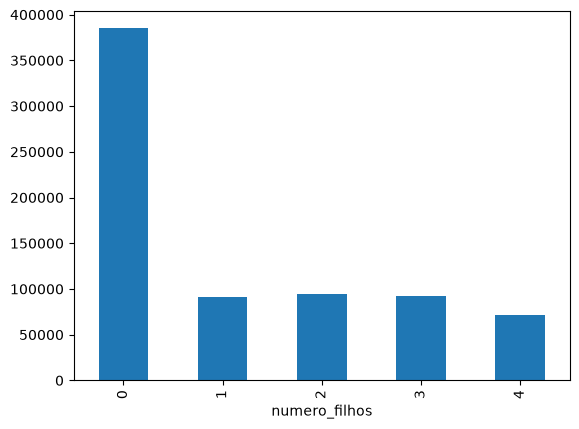

In [ ]:
#gráfico em barras do núm de filhos 

df_base_varejo["numero_filhos"].value_counts().sort_index().plot(kind="bar")

<Axes: title={'center': 'Distribuição dos registros por número de filhos'}, xlabel='Número de filhos', ylabel='Quantidade de registros'>

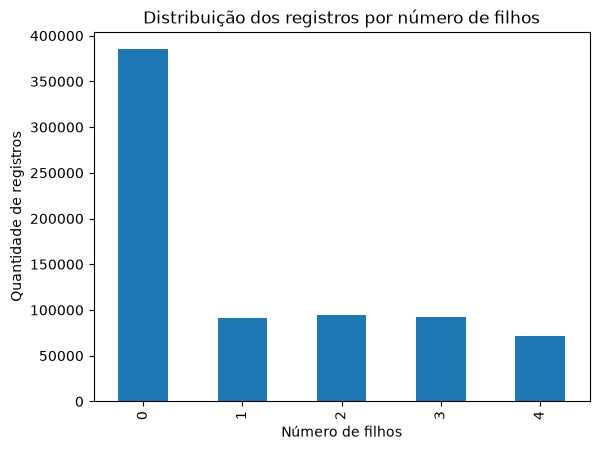

In [ ]:
#gráfico melhorado
#a quantidade de núm de filhos se refere as linhas da base

df_base_varejo["numero_filhos"].value_counts().sort_index().plot(
    kind="bar",
    title="Distribuição dos registros por número de filhos",
    xlabel="Número de filhos",
    ylabel="Quantidade de registros"
)

In [ ]:
#calculando a moda

clientes_unicos["numero_filhos"].mode().tolist()

[0]

In [166]:
clientes_unicos["numero_filhos"].describe()

count    1000.00000
mean        1.13600
std         1.41333
min         0.00000
25%         0.00000
50%         0.00000
75%         2.00000
max         4.00000
Name: numero_filhos, dtype: float64

In [168]:
estatisticas_filhos = pd.Series({
    "Contagem": clientes_unicos["numero_filhos"].count(),
    "Média": clientes_unicos["numero_filhos"].mean(),
    "Mediana": clientes_unicos["numero_filhos"].median(),
    "Desvio padrão": clientes_unicos["numero_filhos"].std(),
    "Moda": clientes_unicos["numero_filhos"].mode().iloc[0],
    "Mínimo": clientes_unicos["numero_filhos"].min(),
    "1º quartil (25%)": clientes_unicos["numero_filhos"].quantile(0.25),
    "2º quartil (50%)": clientes_unicos["numero_filhos"].quantile(0.50),
    "3º quartil (75%)": clientes_unicos["numero_filhos"].quantile(0.75),
    "Máximo": clientes_unicos["numero_filhos"].max()
})

estatisticas_filhos

Contagem            1000.00000
Média                  1.13600
Mediana                0.00000
Desvio padrão          1.41333
Moda                   0.00000
Mínimo                 0.00000
1º quartil (25%)       0.00000
2º quartil (50%)       0.00000
3º quartil (75%)       2.00000
Máximo                 4.00000
dtype: float64

In [ ]:
#criando uma coluna auxiliar com o mês da compra

df_base_varejo["mes_compra"] = df_base_varejo["data_compra"].dt.to_period("M")

In [106]:
df_base_varejo[["data_compra", "mes_compra"]].head()

,data_compra,mes_compra
0,2019-02-01,2019-02
1,2019-02-01,2019-02
2,2019-02-01,2019-02
3,2019-02-01,2019-02
4,2019-02-01,2019-02


In [107]:
#contando os registros por mes

df_base_varejo["mes_compra"].value_counts().sort_index()

mes_compra
2019-01     6492
2019-02    16153
2019-03     9835
2019-04    16255
2019-05    28115
2019-06    19484
2019-07    10755
2019-08    15918
2019-09    16895
2019-10     9127
2019-11     6120
2019-12    20954
2020-01    20675
2020-02    17173
2020-03    17543
2020-04    15695
2020-05    14011
2020-06    10907
2020-07     8967
2020-08    15935
2020-09    18877
2020-10    25275
2020-11    15079
2020-12    12667
2021-01    23915
2021-02    17150
2021-03    15537
2021-04    14820
2021-05    13198
2021-06    17231
2021-07    23635
2021-08    14945
2021-09    23618
2021-10    28575
2021-11     8684
2021-12    15505
2022-01    23039
2022-02    16654
2022-03    14014
2022-04    12450
2022-05    17475
2022-06    12226
2022-07    17579
2022-08    11224
2022-09     1297
2022-10     2373
2022-11     6192
2022-12    13204
Freq: M, Name: count, dtype: int64

<Axes: title={'center': 'Evolução mensal'}, xlabel='Mês de compra', ylabel='Quantidade de registros'>

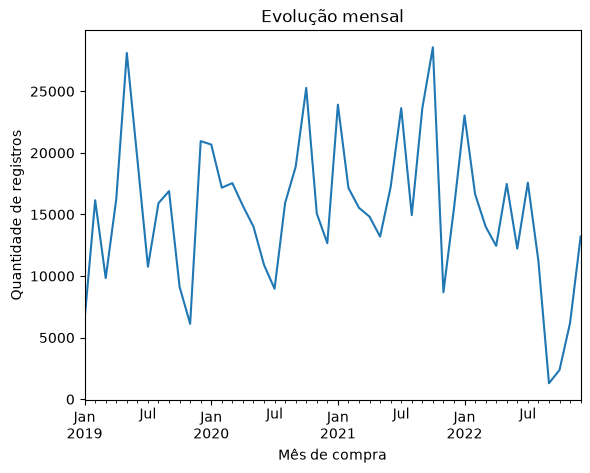

In [110]:
#gráfico de evoluçao mensal

registros_mensais = df_base_varejo.groupby("mes_compra").size()

registros_mensais.plot(
    kind="line",
    title="Evolução mensal",
    xlabel="Mês de compra",
    ylabel="Quantidade de registros"
)

<Axes: title={'center': 'Evolução mensal dos registros'}, xlabel='Mês da compra', ylabel='Quantidade de registros'>

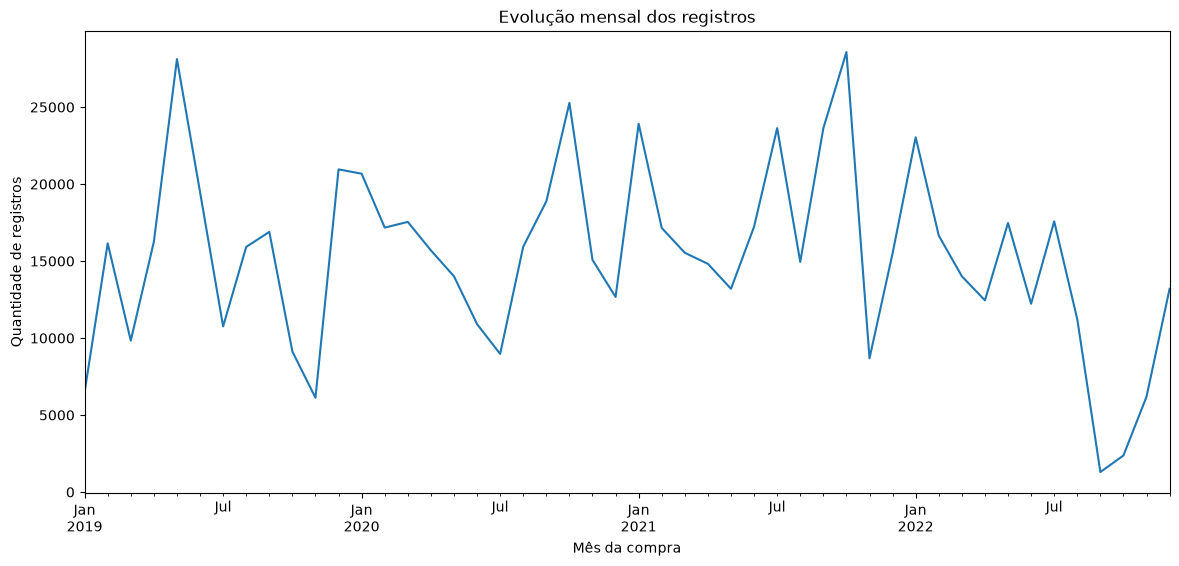

In [117]:
#gráfico melhorado

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

registros_mensais.plot(
    kind="line",
    title="Evolução mensal dos registros",
    xlabel="Mês da compra",
    ylabel="Quantidade de registros"
)

In [119]:
#comparar meses e anos

tabela_mensal = df_base_varejo.pivot_table(
    index=df_base_varejo["data_compra"].dt.year,
    columns=df_base_varejo["data_compra"].dt.month,
    values="numero_compra",
    aggfunc="size"
)

tabela_mensal

data_compra,1,2,3,4,5,6,7,8,9,10,11,12
data_compra,,,,,,,,,,,,
2019,6492,16153,9835,16255,28115,19484,10755,15918,16895,9127,6120,20954
2020,20675,17173,17543,15695,14011,10907,8967,15935,18877,25275,15079,12667
2021,23915,17150,15537,14820,13198,17231,23635,14945,23618,28575,8684,15505
2022,23039,16654,14014,12450,17475,12226,17579,11224,1297,2373,6192,13204


<Axes: title={'center': 'Comparação mensal dos registros por ano'}, xlabel='Mês', ylabel='Quantidade de registros'>

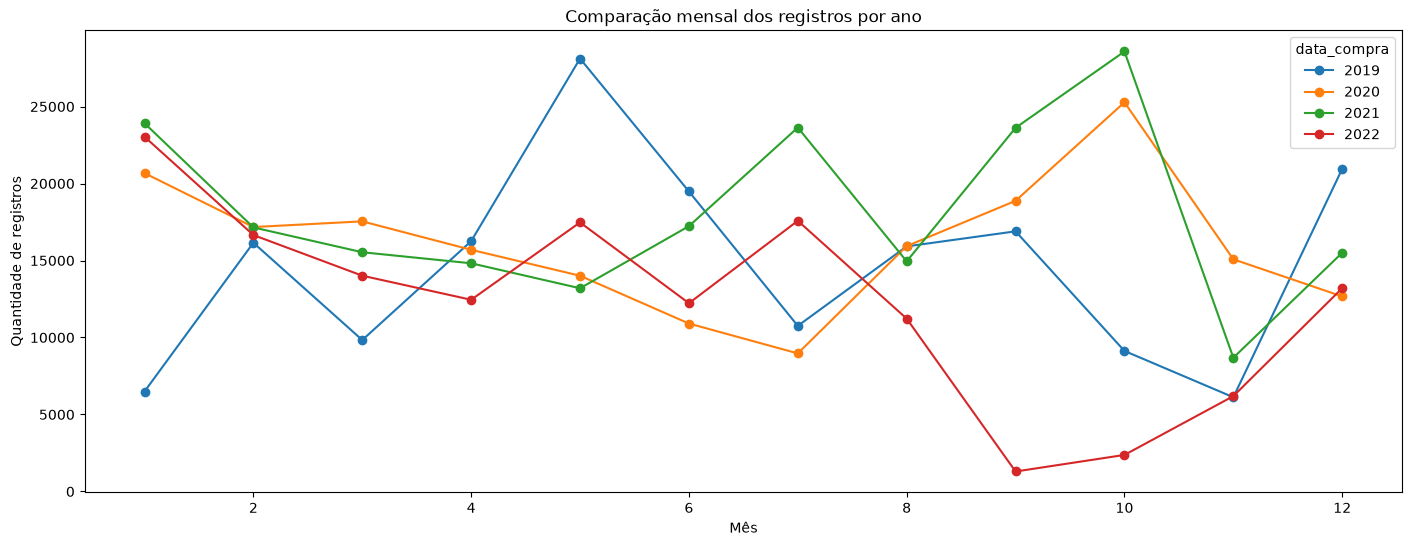

In [124]:
tabela_mensal.T.plot(
    kind="line",
    figsize=(17, 6),
    marker="o",
    title="Comparação mensal dos registros por ano",
    xlabel="Mês",
    ylabel="Quantidade de registros"
)

In [ ]:
#investigando quedas

df_base_varejo[
    df_base_varejo["data_compra"].dt.year == 2022
].groupby(
    df_base_varejo["data_compra"].dt.month
)["data_compra"].agg(
    ["min", "max", "count"]
)

,min,max,count
data_compra,,,
1,2022-01-05,2022-01-31,23039
2,2022-02-03,2022-02-24,16654
3,2022-03-14,2022-03-29,14014
4,2022-04-06,2022-04-30,12450
5,2022-05-01,2022-05-28,17475
6,2022-06-07,2022-06-30,12226
7,2022-07-03,2022-07-31,17579
8,2022-08-05,2022-08-19,11224
9,2022-09-01,2022-09-01,1297


In [ ]:
#setembro e outubro tem registro só de 1 dia

In [ ]:
#contando quantas datas tem em cada mês em 2022

df_base_varejo[
    df_base_varejo["data_compra"].dt.year == 2022
].groupby(
    df_base_varejo["data_compra"].dt.month
)["data_compra"].nunique()

data_compra
1     8
2     6
3     6
4     6
5     7
6     6
7     7
8     4
9     1
10    1
11    3
12    4
Name: data_compra, dtype: int64

In [128]:
df_base_varejo[
    df_base_varejo["data_compra"].dt.year == 2021
].groupby(
    df_base_varejo["data_compra"].dt.month
)["data_compra"].nunique()

data_compra
1     10
2      7
3      8
4      6
5      7
6      8
7      9
8      8
9     10
10    12
11     5
12     7
Name: data_compra, dtype: int64

In [129]:
df_base_varejo[
    df_base_varejo["data_compra"].dt.year == 2020
].groupby(
    df_base_varejo["data_compra"].dt.month
)["data_compra"].nunique()

data_compra
1     10
2     10
3      7
4      7
5      6
6      4
7      5
8      7
9      8
10    11
11     7
12     7
Name: data_compra, dtype: int64

In [130]:
df_base_varejo[
    df_base_varejo["data_compra"].dt.year == 2019
].groupby(
    df_base_varejo["data_compra"].dt.month
)["data_compra"].nunique()

data_compra
1      5
2      6
3      7
4      7
5     13
6      9
7      4
8      9
9      8
10     6
11     5
12     9
Name: data_compra, dtype: int64

In [ ]:
#compilando

df_base_varejo.pivot_table(
    index=df_base_varejo["data_compra"].dt.month,
    columns=df_base_varejo["data_compra"].dt.year,
    values="data_compra",
    aggfunc="nunique"
)

data_compra,2019,2020,2021,2022
data_compra,,,,
1,5,10,10,8
2,6,10,7,6
3,7,7,8,6
4,7,7,6,6
5,13,6,7,7
6,9,4,8,6
7,4,5,9,7
8,9,7,8,4
9,8,8,10,1


In [132]:
df_base_varejo["data_compra"].value_counts().sort_index()

data_compra
2019-01-04     861
2019-01-13    1284
2019-01-19     419
2019-01-23     789
2019-01-29    3139
              ... 
2022-11-06    2899
2022-12-03    2066
2022-12-05    3822
2022-12-07    3553
2022-12-08    3763
Name: count, Length: 333, dtype: int64

In [133]:
df_base_varejo[
    df_base_varejo["data_compra"] >= "2022-09-01"
].groupby("data_compra").size()

data_compra
2022-09-01    1297
2022-10-04    2373
2022-11-02    1351
2022-11-04    1942
2022-11-06    2899
2022-12-03    2066
2022-12-05    3822
2022-12-07    3553
2022-12-08    3763
dtype: int64

In [134]:
df_base_varejo.groupby(
    df_base_varejo["data_compra"].dt.year
)["numero_compra"].nunique()

data_compra
2019    4483
2020    4794
2021    5505
2022    3689
Name: numero_compra, dtype: int64

In [135]:
#quantos produtos aparecem em cada compra?

df_base_varejo.groupby("numero_compra")["sku_produto"].nunique().describe()

count    18471.000000
mean        39.708029
std         21.336498
min          1.000000
25%         22.000000
50%         41.000000
75%         58.000000
max         81.000000
Name: sku_produto, dtype: float64

In [136]:
df_base_varejo.groupby("numero_compra")["id_cliente"].nunique().value_counts().sort_index()

id_cliente
1    18471
Name: count, dtype: int64

In [137]:
pd.crosstab(
    df_base_varejo["estado_civil"],
    df_base_varejo["numero_filhos"]
)

numero_filhos,0,1,2,3,4
estado_civil,,,,,
1,95234,15532,14063,20739,26442
2,85391,15733,26685,27129,17345
3,100815,18603,23129,19247,27254
4,103546,28906,23829,22925,0
5,0,12071,6462,2367,0


In [ ]:
df_base_varejo.drop_duplicates(
    subset=["id_cliente"]
)[["id_cliente", "estado_civil", "numero_filhos"]].groupby(
    ["estado_civil", "numero_filhos"]
).size().unstack(fill_value=0)

numero_filhos,0,1,2,3,4
estado_civil,,,,,
1,127,21,20,26,39
2,119,22,39,35,23
3,135,25,31,24,35
4,146,40,32,33,0
5,0,17,8,3,0


In [ ]:
#pra ver se algum cliente aparece associado a + de 1 estado civil ou número de filhos

df_base_varejo.groupby("id_cliente")[
    ["estado_civil", "numero_filhos"]
].nunique().max()

estado_civil     1
numero_filhos    1
dtype: int64

In [ ]:
#calcular correlação entre variaveis numéricas

df_base_varejo.drop_duplicates(
    subset="id_cliente"
)["numero_filhos"].describe()

count    1000.00000
mean        1.13600
std         1.41333
min         0.00000
25%         0.00000
50%         0.00000
75%         2.00000
max         4.00000
Name: numero_filhos, dtype: float64

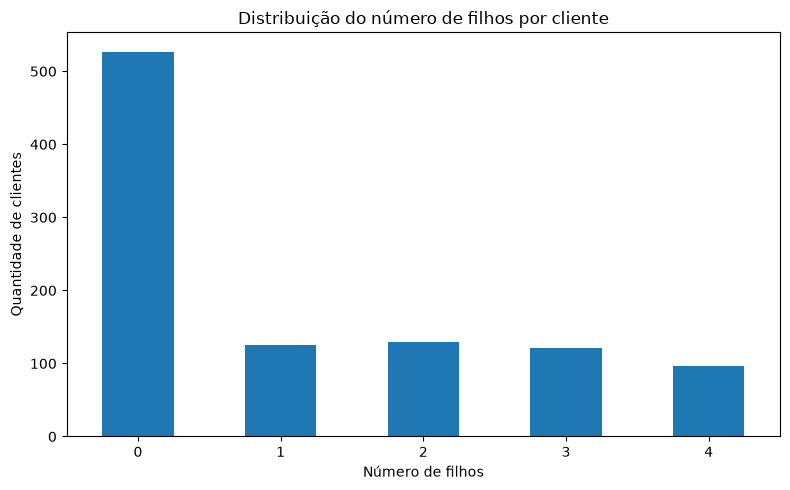

In [145]:
#criando um histograma da distribuição do número de filhos por cliente

import matplotlib.pyplot as plt

clientes_unicos = df_base_varejo.drop_duplicates(
    subset="id_cliente"
)

clientes_unicos["numero_filhos"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 5),
    title="Distribuição do número de filhos por cliente",
    xlabel="Número de filhos",
    ylabel="Quantidade de clientes"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [146]:
df_base_varejo.select_dtypes(include="number").columns.tolist()

['numero_compra', 'id_cliente', 'estado_civil', 'numero_filhos', 'sku_produto']

In [147]:
#pra calcular quantas compras distintas cada cliente fez

compras_por_cliente = df_base_varejo.groupby(
    "id_cliente"
)["numero_compra"].nunique()

compras_por_cliente.describe()

count    1000.000000
mean       18.471000
std         4.338431
min         7.000000
25%        15.000000
50%        18.000000
75%        21.000000
max        34.000000
Name: numero_compra, dtype: float64

In [149]:
perfil_clientes = df_base_varejo.drop_duplicates(
    subset="id_cliente"
)[["id_cliente", "numero_filhos"]].copy()

perfil_clientes["quantidade_compras"] = (
    perfil_clientes["id_cliente"]
    .map(compras_por_cliente)
)

perfil_clientes.head()

,id_cliente,numero_filhos,quantidade_compras
0,534,1,22
52,279,2,22
67,290,0,12
149,323,3,16
220,957,3,24


In [150]:
perfil_clientes[
    ["id_cliente", "numero_filhos", "quantidade_compras"]
].head(10).to_string(index=False)

' id_cliente  numero_filhos  quantidade_compras\n        534              1                  22\n        279              2                  22\n        290              0                  12\n        323              3                  16\n        957              3                  24\n         49              0                  22\n        906              0                  12\n        653              0                  10\n        842              2                  22\n        616              2                  19'

<Axes: title={'center': 'Número de filhos e quantidade de compras por cliente'}, xlabel='Número de filhos', ylabel='Quantidade de compras distintas'>

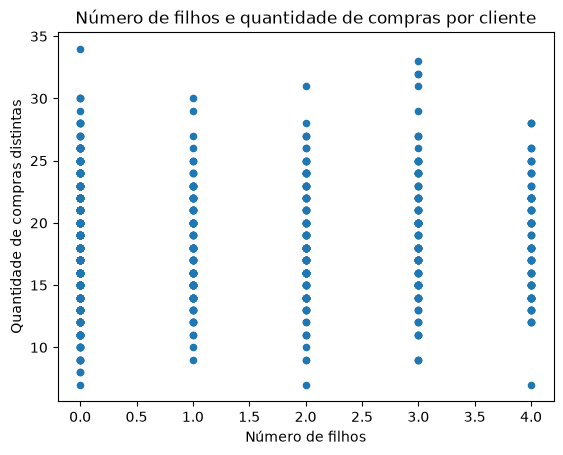

In [151]:
perfil_clientes.plot(
    kind="scatter",
    x="numero_filhos",
    y="quantidade_compras",
    title="Número de filhos e quantidade de compras por cliente",
    xlabel="Número de filhos",
    ylabel="Quantidade de compras distintas"
)

In [153]:
perfil_clientes[
    ["numero_filhos", "quantidade_compras"]
].corr(method="spearman")

,numero_filhos,quantidade_compras
numero_filhos,1.000000,0.000749
quantidade_compras,0.000749,1.000000


In [154]:
#investigando o segmento economico

perfil_segmento = df_base_varejo.drop_duplicates(
    subset="id_cliente"
)[["id_cliente", "segmento_economico"]].copy()

perfil_segmento["quantidade_compras"] = (
    perfil_segmento["id_cliente"].map(compras_por_cliente)
)

perfil_segmento.groupby("segmento_economico")[
    "quantidade_compras"
].describe()

,count,mean,std,min,25%,50%,75%,max
segmento_economico,,,,,,,,
A,84.0,17.761905,4.230181,8.0,14.75,17.5,21.0,28.0
B,645.0,18.361240,4.234733,7.0,15.00,18.0,21.0,33.0
C,271.0,18.952030,4.577067,7.0,16.00,19.0,22.0,34.0


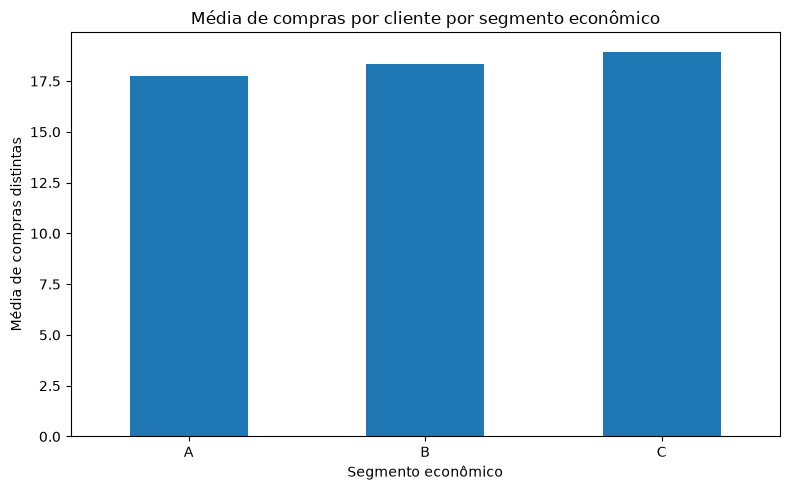

In [155]:
#visualizando a comparaçao

perfil_segmento.groupby("segmento_economico")[
    "quantidade_compras"
].mean().plot(
    kind="bar",
    figsize=(8, 5),
    title="Média de compras por cliente por segmento econômico",
    xlabel="Segmento econômico",
    ylabel="Média de compras distintas"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

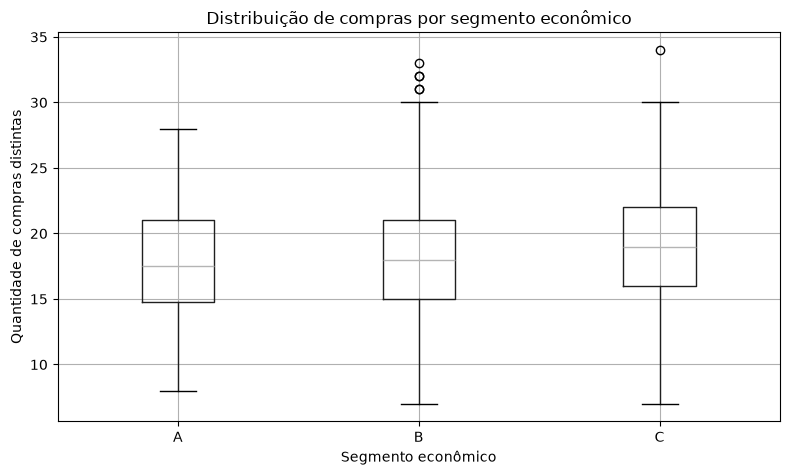

In [ ]:
#comparando nº de filhos com nº de compras por cliente
perfil_segmento.boxplot(
    column="quantidade_compras",
    by="segmento_economico",
    figsize=(8, 5)
)

plt.title("Distribuição de compras por segmento econômico")
plt.suptitle("")
plt.xlabel("Segmento econômico")
plt.ylabel("Quantidade de compras distintas")
plt.tight_layout()
plt.show()

In [159]:
perfil_segmento["segmento_economico"].value_counts().sort_index()

segmento_economico
A     84
B    645
C    271
Name: count, dtype: int64

In [160]:
df_base_varejo["categoria_produto"].value_counts()

categoria_produto
ALIMENTOS     384197
HIGIENE       137702
LIMPEZA       128632
BEBIDAS        38264
PET            28553
ACESSORIOS     12871
#N/D            3228
Name: count, dtype: int64

In [ ]:
#de novo

(df_base_varejo["categoria_produto"].value_counts(normalize=True) * 100).round(2)

categoria_produto
ALIMENTOS     52.38
HIGIENE       18.77
LIMPEZA       17.54
BEBIDAS        5.22
PET            3.89
ACESSORIOS     1.75
#N/D           0.44
Name: proportion, dtype: float64

In [ ]:
#comparando os percentuais de cada categoria entre os segmentos A, B e C

pd.crosstab(
    df_base_varejo["segmento_economico"],
    df_base_varejo["categoria_produto"],
    normalize="index"
).mul(100).round(2)

categoria_produto,#N/D,ACESSORIOS,ALIMENTOS,BEBIDAS,HIGIENE,LIMPEZA,PET
segmento_economico,,,,,,,
A,0.44,1.75,52.14,5.31,18.98,17.53,3.86
B,0.44,1.74,52.40,5.20,18.77,17.52,3.93
C,0.44,1.78,52.41,5.23,18.72,17.59,3.82


In [ ]:
# Minhas decisões na limpeza de dados:

# Eu removi quatro colunas totalmente vazias pois não continham informações úteis;
# Encontrei 3.650 registros associados ao SKU 107 com categoria e nome indicados como #N/D. Mantive eles, pois não havia informações suficientes para corrigir os dados com segurança.
# Identifiquei 96.553 linhas duplicadas adicionais. Eu mantive apenas uma ocorrência de cada registro exato, reduzindo a base de 830.000 para 733.447 linhas.


# Resultado das análises que fiz:

# As médias são próximas entre A (17,76), B (18,36) e C (18,95). O segmento C apresenta a maior média, mas a diferença é pequena.
# A distribuição percentual das categorias é muito parecida entre A, B e C. Não vi diferenças expressivas na composição dos registros por categoria.


# Mil clientes únicos foram analisados; a mediana e a moda do número de filhos são zero.
# O segmento B reúne 645 clientes, C reúne 271 e A reúne 84.
# A base tem cobertura incompleta de datas, então não é seguro interpretar as diferenças de registros mensais como variações reais nas vendas.



## CONCLUSÕES ##

# Depois de remover os registros duplucados, a base ficou com 1.000 clientes únicos.
# Na distribuição por gênero os números ficaram relativamente equilibrados, com 52,14% de registros do gênero F e 47,86% do gênero M.
# O segmento econômico que mais concentra a quantidade de clientes é o B, seguido pelos segmentos C e A.
# A média de compras por cliente é semelhante entre os segmentos econômicos, variando de aproximadamente 17,76 a 18,95 compras.
# O número de filhos varia de 0 a 4, sendo zero o valor da mediana e da moda.
# Ficaram algumas limitações na base, como produtos sem categoria identificada (#N/D) e cobertura incompleta de datas, que exige cautela ao comparar períodos.